# An ensemble of structures as one sample

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/igbaskin/cmf-qsar/blob/main/docs/tutorials/12_an_ensemble_of_structures.ipynb)

In the earlier notebooks a sample was one structure. Often it is not. A liquid is not one
molecule in one pose. The property that an experiment measures is an average over a very large
number of structures. The program takes such a set of structures as one **ensemble**: a list of
structures with a weight for each. This notebook shows how a file says it, why it costs almost
nothing, and what the ensemble is worth.

The data are 62 electrolytes, each of lithium hexafluorophosphate (LiPF6) in a mixture of organic
solvents. For each one, a simulation of the liquid gave about 16 **solvation shells**: the
molecules and ions around one lithium ion, with a weight for each shell. The two targets are the
conductivity at 298 K (as log10) and the activation energy of the conductivity, in kJ/mol. The
notebook asks three questions.

1. How does one sample hold several structures, when their atoms are not the same?
2. Why is the mean field of an ensemble cheap?
3. Is the ensemble worth more than one structure, and are its weights worth more than equal ones?

The notebook runs the fits itself and reads the long tables from the stored results of
`benchmarks/run_ensembles.py` and `benchmarks/run_shells.py`.

Running time: about eight minutes.

In [1]:
# Run this cell first. On Google Colab it fetches the repository and installs the package;
# on a local checkout it only moves to the repository root, so that the example paths work.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("cmf-qsar"):
        subprocess.run(["git", "clone", "-q", "https://github.com/igbaskin/cmf-qsar.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "./cmf-qsar", "py3Dmol"], check=True)
    os.chdir("cmf-qsar")
else:
    while not os.path.exists("pyproject.toml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")
print("working in", os.getcwd())

working in C:\Users\baski\work\claude\cmf


## The data: one file, 989 records, 62 samples

`examples/electrolyte/` holds the formulations and the sampled shells (one file per electrolyte).
`file_stage` in `benchmarks/run_ensembles.py` writes all of them into one SD file, one record per
shell. Each record carries the name of its electrolyte, the weight of the shell and the two
targets. Nothing of the code that cut the shells out of the simulation is used to read the file
back. The next cell writes the file and reads it with the general entry,
`load_dataset(..., ensemble_by=..., member_weight=...)`.

In [2]:
import contextlib
import io
import json
import os
import sys

os.environ["CMF_KERNEL_CACHE"] = "0"
sys.path.insert(0, "benchmarks")

import matplotlib.pyplot as plt
import numpy as np
from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem

RDLogger.DisableLog("rdApp.*")
import run_ensembles as en                  # the file, the rows and the fits of this benchmark
import run_shells as RS                     # BT5: the series, the folds and the nested cross-validation
from cmfqsar.dataio import load_dataset
from cmfqsar.ensembles import ensemble_molecule, is_packed, member_sizes, members_of, n_members, stored_weights
from cmfqsar.fields import AtomTable, FieldSet, build_fields
from cmfqsar.model import CMFModel

rows = RS.load_series()
with contextlib.redirect_stdout(io.StringIO()):
    written = en.file_stage()
print("%d electrolytes over %d solvent compositions, molality %.2f to %.2f mol/kg" % (
    len(rows), len({r["composition"] for r in rows}), min(r["molality"] for r in rows), max(r["molality"] for r in rows)))
print("%d records written, %d to %d shells per electrolyte, %d to %d atoms in a shell" % (
    written["records"], written["members_per_electrolyte"]["min"], written["members_per_electrolyte"]["max"],
    written["atoms_per_member"]["min"], written["atoms_per_member"]["max"]))
print("electrolytes whose shells do not all have the same atoms: %d of %d" % (
    written["electrolytes_whose_members_differ_in_atoms"], written["electrolytes"]))

ds = load_dataset(en.FILE, activity_prop="ea_298", ensemble_by=en.GROUP, member_weight=en.WEIGHT)
print()
print("read back: %d samples, %d of them packed ensembles, %.1f shells on average" % (
    len(ds.mols), sum(is_packed(m) for m in ds.mols), np.mean([n_members(m) for m in ds.mols])))

62 electrolytes over 22 solvent compositions, molality 0.24 to 2.37 mol/kg
989 records written, 15 to 16 shells per electrolyte, 15 to 94 atoms in a shell
electrolytes whose shells do not all have the same atoms: 62 of 62



read back: 62 samples, 62 of them packed ensembles, 16.0 shells on average


Every one of the 62 electrolytes has shells with different atoms. A shell with a solvent molecule
more or less is a different molecule, so the shells are not conformations of one molecule. The
reader keeps them anyway: it **packs** the members side by side into one RDKit molecule and stores
where each member starts and what weight it has. The next cells look at one electrolyte, and then
at the same rule on two tiny molecules.

electrolyte LiPF6_DEC20_PC80_m0p282: 16 shells in one molecule of 1060 atoms
atoms in each shell: [71, 84, 47, 47, 47, 60, 47, 47, 84, 84, 71, 71, 71, 84, 79, 66]
weights (they sum to 1.000): [0.277, 0.248, 0.152, 0.109, 0.035, 0.03, 0.014, 0.011, 0.007, 0.003, 0.001, 0.001, 0.0, 0.0, 0.057, 0.056]


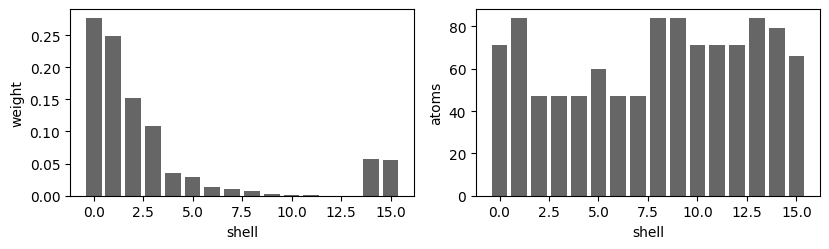

In [3]:
mol = ds.mols[0]
sizes = member_sizes(mol)
weights = stored_weights(mol)
print("electrolyte %s: %d shells in one molecule of %d atoms" % (ds.names[0], n_members(mol), mol.GetNumAtoms()))
print("atoms in each shell:", sizes)
print("weights (they sum to %.3f):" % weights.sum(), np.round(weights, 3).tolist())

fig, axes = plt.subplots(1, 2, figsize=(8.4, 2.6))
axes[0].bar(range(len(weights)), weights, color="0.4")
axes[0].set_xlabel("shell")
axes[0].set_ylabel("weight")
axes[1].bar(range(len(sizes)), sizes, color="0.4")
axes[1].set_xlabel("shell")
axes[1].set_ylabel("atoms")
plt.tight_layout()
plt.show()

In [4]:
# the same rule on two tiny molecules: members with the same atoms become conformations,
# members with other atoms are packed
def structure(smiles, seed):
    m = Chem.AddHs(Chem.MolFromSmiles(smiles))
    AllChem.EmbedMolecule(m, randomSeed=seed)
    return m


ethanol = [structure("CCO", 1), structure("CCO", 2)]
methanol = structure("CO", 3)
same = ensemble_molecule(ethanol, weights=[3.0, 1.0])
other = ensemble_molecule([ethanol[0], methanol], weights=[3.0, 1.0])
print("two structures of ethanol: packed %s, %d atoms, %d conformations, weights %s" % (
    is_packed(same), same.GetNumAtoms(), same.GetNumConformers(), same.GetProp("conformer_weights")))
print("ethanol and methanol:      packed %s, %d atoms in %d members of %s atoms, weights %s" % (
    is_packed(other), other.GetNumAtoms(), n_members(other), member_sizes(other), np.round(stored_weights(other), 2).tolist()))
back = members_of(other)
print("members_of gives the members back, with %s atoms" % [m.GetNumAtoms() for m in back])

two structures of ethanol: packed 0, 9 atoms, 2 conformations, weights 3.0,1.0
ethanol and methanol:      packed 1, 15 atoms in 2 members of [9, 6] atoms, weights [3.0, 1.0]
members_of gives the members back, with [9, 6] atoms


**A trap.** After `members_of`, the record property `member_weight` of every member shows the
weight of the first member, because the members are cut out of a packed molecule that has one set
of properties. The weights that the model uses are the ones the packed molecule stores. Read them
with `stored_weights`, as the cell above does, and not from the property of a member.

## Why the mean field is cheap

A field is a sum of Gaussian functions, one on each atom. The overlap kernel is **bilinear**: it
is linear in each of its two fields. So the weighted mean of the fields of the shells is itself a
field. Its atoms are the atoms of all the shells, and each keeps its weight times the weight of its
shell. The kernel between two such mean fields is then exactly the weighted mean of the
shell-to-shell kernels:

    K(mean of A, mean of B) = sum over i and j of  w_i  w_j  K(A_i, B_j).

The right side needs 16 x 16 kernel values for two electrolytes. The left side needs one, on a
longer list of atoms. The cell below checks that the two agree. It builds the fields of the
shells of two electrolytes one by one, computes the overlap of every pair of shells for each of
the five fields, and compares the weighted mean with the overlap of the two ensembles that the
general path builds.

In [5]:
fieldset = FieldSet.create(physchem=list(RS.FIELDS), alpha=1.0, charge_model="gasteiger",
                           conformers="ensemble", conformer_weighting="given")
single = FieldSet.create(physchem=list(RS.FIELDS), alpha=1.0, charge_model="gasteiger")
pair = [0, 1]
shell_fields, shell_weights, owner = [], [], []
for k in pair:
    members = members_of(ds.mols[k])
    w = np.asarray(stored_weights(ds.mols[k]), float)
    for member, wi in zip(members, w / w.sum()):
        shell_fields.append(build_fields(member, single, name="shell"))
        shell_weights.append(wi)
        owner.append(k)
shell_weights, owner = np.array(shell_weights), np.array(owner)
ensembles = [build_fields(ds.mols[k], fieldset, name=ds.names[k]) for k in pair]

model = CMFModel(fieldset=single, method="krr", kernel_source="fields", normalize=False)
K_shells = np.moveaxis(np.asarray(model.prepare_training_kernels(AtomTable.from_molecules(shell_fields))), 0, -1)
K_ensembles = np.moveaxis(np.asarray(model.prepare_training_kernels(AtomTable.from_molecules(ensembles))), 0, -1)

print("%d shells of two electrolytes: %d x %d shell-to-shell overlaps for each field, against 2 x 2 for the ensembles" % (
    len(owner), len(owner), len(owner)))
print("%-14s %12s %12s %20s" % ("field", "mean of shells", "ensemble", "relative difference"))
for f, name in enumerate(fieldset.names):
    mean_of_shells = np.array([[(shell_weights[owner == a][:, None] * shell_weights[owner == b][None, :]
                                 * K_shells[..., f][np.ix_(owner == a, owner == b)]).sum() for b in pair] for a in pair])
    top = np.abs(K_ensembles[..., f]).max()
    if top == 0:
        print("%-14s %12s %12s %20s" % (name, "0", "0", "no atom of this type"))
        continue
    print("%-14s %12.4f %12.4f %20.1e" % (name, mean_of_shells[0, 1], K_ensembles[0, 1, f],
                                          np.abs(mean_of_shells - K_ensembles[..., f]).max() / top))

32 shells of two electrolytes: 32 x 32 shell-to-shell overlaps for each field, against 2 x 2 for the ensembles
field          mean of shells     ensemble  relative difference
electrostatic        4.3466       4.3466              1.4e-15
steric              80.9139      80.9139              8.1e-16
hydrophobic         30.4890      30.4890              1.4e-15
hba                 14.7370      14.7370              5.7e-16
hbd                       0            0 no atom of this type


The relative difference is zero for every field. The ensemble is not an approximation of the mean
of the shells. It is the same number. The same argument keeps the kernel matrix positive definite
and the model linear in the mean field, so the co-field and the contribution of each atom keep
their meaning.

## What the benchmark says: the general path gives the numbers of item BT5

Item BT5 measured these electrolytes with code written for shells. Item MS5 made the general
entry above, and its gate is that it gives the same numbers from the same shells. The table below
is read from `benchmarks/results/ensembles/gate.json`. It lists the mean absolute error of the
two shell models of BT5, with each kind of fold, as stored by BT5 and as given by the general
path.

In [6]:
gate = json.load(open(os.path.join(en.RESULTS, "gate.json")))
names = {"log10_k_298": "log10 conductivity", "ea_298": "activation energy, kJ/mol"}
print("%-26s %-15s %-12s %10s %10s %12s" % ("target", "folds", "model", "stored", "general", "difference"))
for r in gate["readings"]:
    print("%-26s %-15s %-12s %10.4f %10.4f %12.1e" % (names[r["target"]], r["split"], r["model"], r["stored_mae"],
                                                       r["general_mae"], r["general_difference"]))
print("gate met:", gate["gate_met"])

target                     folds           model            stored    general   difference
log10 conductivity         random          shells           0.1147     0.1147      0.0e+00
log10 conductivity         random          shells-free      0.1091     0.1091      0.0e+00
log10 conductivity         by-composition  shells           0.1130     0.1130      0.0e+00
log10 conductivity         by-composition  shells-free      0.1034     0.1034      0.0e+00
activation energy, kJ/mol  random          shells           2.2357     2.2357      0.0e+00
activation energy, kJ/mol  random          shells-free      1.6121     1.6121      0.0e+00
activation energy, kJ/mol  by-composition  shells           2.9028     2.9028      0.0e+00
activation energy, kJ/mol  by-composition  shells-free      1.6845     1.6845      0.0e+00
gate met: True


## A model, run here

The alignment-free model of BT5 is the better of its two. It reads the ensemble through the
rotation-invariant kernel of the second notebook, so no frame is needed. It is mixed in equal
parts with a kernel on the **molality** (the concentration of the salt), because conductivity
depends on the concentration strongly and a model that cannot see it would be a straw man. The
width of the fields and the ridge are chosen inside each training fold. The folds of the
**by-composition** design keep every solvent mixture out of the training part when it is in the
test part, so the question is the one that matters: describe an electrolyte whose solvent mixture
the model has not seen.

`members_rows` builds the rows of the electrolytes at the four widths through the general path
(about a minute). `RS.nested` is the nested cross-validation of BT5. The cell compares its result
for the activation energy with the record that BT5 stored.

In [7]:
y = np.array([r["ea_298"] for r in rows], float)
labels = [str(r["composition"]) for r in rows]
folds = RS.grouped_folds(labels)
stored = json.load(open(en.STORED))
stored_ea = stored["models"]["ea_298|by-composition"]
print("predicting the mean costs %.2f kJ/mol; the target runs from %.1f to %.1f" % (np.mean(np.abs(y - y.mean())), y.min(), y.max()))
print()

entry_16 = en.members_rows("given", 16)
live = RS.nested(entry_16, RS.descriptors(rows, "shells-free"), y, folds, labels, (RS.MIX,), label="16 shells, given weights", unit="kJ/mol")
print("   stored by BT5 for the same model: %.4f; largest difference over every number of the record: %.1e" % (
    stored_ea["shells-free"]["mae_mean"], en._largest_difference(live, stored_ea["shells-free"])))
for model_name in ("conditions", "composition"):
    ref = RS.nested(None, RS.descriptors(rows, model_name), y, folds, labels, (RS.MIX,), label=model_name, unit="kJ/mol")

predicting the mean costs 3.53 kJ/mol; the target runs from 5.5 to 37.8



    16 shells, given weights MAE 1.685 +/- 0.321 kJ/mol, R2 +0.825  (0 s)


   stored by BT5 for the same model: 1.6845; largest difference over every number of the record: 0.0e+00
    conditions               MAE 3.035 +/- 1.156 kJ/mol, R2 +0.218  (0 s)


    composition              MAE 1.429 +/- 0.704 kJ/mol, R2 +0.841  (0 s)


The activation energy of these 62 electrolytes runs from 5.5 to 37.8 kJ/mol, and predicting the mean
costs 3.53 kJ/mol. The model that reads 16 shells reaches 1.685 kJ/mol with the folds by
composition. The cell shows that this is the number BT5 stored, to the last digit: the largest
difference over every number of the record is zero, and that includes the error of each
electrolyte and the settings chosen in each fold.

The two references use no field at all. The molality alone gives 3.035 kJ/mol, which is hardly
better than the mean. The molality with the solvent fractions, called the **composition**, gives
1.429 kJ/mol. The composition is therefore the number that a model of the shells has to meet, and
the shell model is behind it by 0.26 kJ/mol. The paired interval in the stored table below says
whether that is more than noise.

## How many members, and with which weights

The ensemble has up to 16 shells with unequal weights. Two questions follow that the gate does not
ask. Does the model need all the shells, or does the heaviest one do as well? And do the given
weights help, or would equal weights do? The program has a setting for both: `max_conformers`
keeps the members of largest weight, and `conformer_weighting` is `given` (the weights of the
file) or `uniform` (equal weights). The cell below runs one variant with the same model and the
same folds: the single heaviest shell. The other variants, equal weights among them, are in the stored table below, because each of the 16-shell variants takes about four minutes to build.

In [8]:
variants = {"1 shell, the heaviest": ("given", 1)}
live_variants = {"16 shells, given weights": live}
for label, (weighting, keep) in variants.items():
    entry = en.members_rows(weighting, keep)
    live_variants[label] = RS.nested(entry, RS.descriptors(rows, "shells-free"), y, folds, labels, (RS.MIX,), label=label, unit="kJ/mol")
print()
print("gain of the variant over 16 shells with given weights (positive: the variant has the smaller error),")
print("mean over the 62 electrolytes, with the 95 % interval of rule 4:")
for label in variants:
    iv = RS.paired_interval(live["abs_errors"], live_variants[label]["abs_errors"])
    print("   %-26s %+.3f kJ/mol  [%+.3f, %+.3f]" % (label, iv["mean"], iv["low"], iv["high"]))

    1 shell, the heaviest    MAE 2.154 +/- 0.436 kJ/mol, R2 +0.677  (0 s)



gain of the variant over 16 shells with given weights (positive: the variant has the smaller error),
mean over the 62 electrolytes, with the 95 % interval of rule 4:
   1 shell, the heaviest      -0.474 kJ/mol  [-0.851, -0.091]


The single heaviest shell is clearly worse than the 16 shells. Its error is 2.154 kJ/mol against
1.685, and the difference, -0.474 [-0.851, -0.091] kJ/mol, does not contain zero. (The number is
negative because the cell reports the gain of the variant over the 16 shells.) So on the activation
energy the ensemble gives something that one shell does not.

## All variants, from the stored run

`python benchmarks/run_ensembles.py --stage members` runs all six variants for both targets and
both kinds of folds, with the references. The table reads its stored result
(`benchmarks/results/ensembles/members.json`). The gain is the paired gain of rule 4: positive
when the variant has the smaller error.

log10 conductivity, random folds
   model                               MAE   gain over 1 shell [95 % interval]
   conditions (no fields)           0.1360
   composition (no fields)          0.0621
   1 shell, the heaviest            0.1098   
   2 shells                         0.1038   +0.0061 [-0.0076, +0.0199]
   4 shells                         0.1102   -0.0002 [-0.0097, +0.0093]
   8 shells                         0.0946   +0.0152 [-0.0013, +0.0333]
   16 shells, given weights         0.1091   +0.0010 [-0.0191, +0.0217]
   16 shells, equal weights         0.1075   +0.0023 [-0.0239, +0.0272]

log10 conductivity, by-composition folds
   model                               MAE   gain over 1 shell [95 % interval]
   conditions (no fields)           0.1373
   composition (no fields)          0.0748
   1 shell, the heaviest            0.1157   
   2 shells                         0.1250   -0.0086 [-0.0218, +0.0046]
   4 shells                         0.1261   -0.0103 [-0.0208, +0.0005]

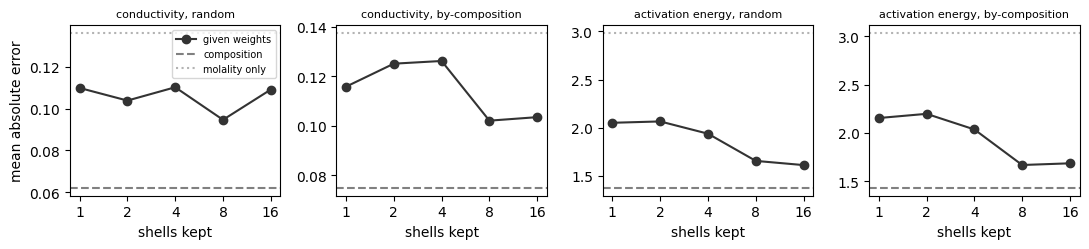

In [9]:
members = json.load(open(os.path.join(en.RESULTS, "members.json")))
labels_variant = {"given-1": "1 shell, the heaviest", "given-2": "2 shells", "given-4": "4 shells",
                  "given-8": "8 shells", "given-16": "16 shells, given weights", "uniform-16": "16 shells, equal weights"}
for key, recs in members["models"].items():
    target, split = key.split("|")
    refs = members["references"][key]
    comp = members["comparisons"][key]
    print("%s, %s folds" % (names[target], split))
    print("   %-28s %10s   %s" % ("model", "MAE", "gain over 1 shell [95 % interval]"))
    for model_name in ("conditions", "composition"):
        print("   %-28s %10.4f" % (model_name + " (no fields)", refs[model_name]["mae_mean"]))
    for v in members["variants"]:
        g = comp.get("%s vs given-1" % v)
        print("   %-28s %10.4f   %s" % (labels_variant[v], recs[v]["mae_mean"],
              "%+.4f [%+.4f, %+.4f]" % (g["mean"], g["low"], g["high"]) if g else ""))
    print()

fig, axes = plt.subplots(1, 4, figsize=(11, 2.6), sharex=True)
counts = [1, 2, 4, 8, 16]
for ax, (key, recs) in zip(axes, members["models"].items()):
    target, split = key.split("|")
    ax.plot(counts, [recs["given-%d" % k]["mae_mean"] for k in counts], "o-", color="0.2", label="given weights")
    ax.axhline(members["references"][key]["composition"]["mae_mean"], color="0.5", linestyle="--", label="composition")
    ax.axhline(members["references"][key]["conditions"]["mae_mean"], color="0.7", linestyle=":", label="molality only")
    ax.set_xscale("log", base=2)
    ax.set_xticks(counts)
    ax.set_xticklabels([str(k) for k in counts])
    ax.set_title("%s, %s" % ("conductivity" if target == "log10_k_298" else "activation energy", split), fontsize=8)
    ax.set_xlabel("shells kept")
axes[0].set_ylabel("mean absolute error")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

Five readings of the table.

1. **Activation energy: the error falls as shells are added.** It goes from 2.05 and 2.15 kJ/mol with
   one shell to 1.61 and 1.68 with 16. The gain over one shell is clear of zero from 8 shells
   (+0.41 and +0.49), and not with 2 or 4 shells (-0.04 to +0.12, with intervals that contain
   zero). So 4 shells are not enough, and 8 are about as good as 16.
2. **The weights do not matter.** Equal weights give 1.607 and 1.711 against 1.612 and 1.685 with
   the given weights. With 62 electrolytes the test cannot tell them apart.
3. **Conductivity: the shells add nothing.** Every gain over one shell is within 0.021 and every
   interval contains zero.
4. **The composition is the better model.** On the conductivity it is clearly below every shell
   model (0.062 and 0.075 against 0.095 or more). On the activation energy it is also below the
   16 shells (1.374 and 1.429 against 1.612 and 1.685), but the interval of the difference,
   -0.24 [-0.57, +0.11] and -0.25 [-0.59, +0.12], contains zero.
5. **The molality alone is far behind** (2.98 and 3.04 kJ/mol), so the shells and the composition
   both add a great deal to it.

## What this shows and what it does not

**What it shows.**

- A sample can be a distribution of structures with weights, and the structures need not have the
  same atoms. A file says it with a name per sample and a weight per record. A single structure is
  the special case of one member.
- The kernel between two ensembles is exactly the weighted mean of the kernels between their
  members. The cell shows a relative difference of 1e-15 or less in every field, which is rounding.
  An ensemble of 16 costs one kernel evaluation, not 256.
- The general entry gives the numbers of item BT5 to the last digit, for both targets and both
  kinds of folds.
- On the activation energy it is worth keeping the ensemble: 16 shells gain about 0.45 kJ/mol over
  the heaviest one, clear of zero, and 8 shells are enough. The given weights add nothing over
  equal ones.

**What it does not show.**

- That the shells beat the composition. They do not: they are clearly behind it on the
  conductivity and, on the activation energy, behind it by an amount that the intervals do not
  separate from zero.
- That the given weights are wrong. Sixty-two electrolytes cannot separate them from equal weights.
- Anything beyond one salt. All 62 electrolytes hold LiPF6, in 22 solvent compositions, and the
  folds by composition leave only a few compositions out at a time.
- What happens when the members are not chosen by weight. Only the members of largest weight were
  tried.

An ensemble is cheap and exact, and on this series it is worth what the composition of the liquid
already says, no more.